# Lab 2 — What Did the Campaign Deliver?
Name: Volkov Oleksii | Group: KM-42

## Setup

In [29]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


### WATCH OUT
The Lab 1 rules still hold: persons are `R` + `L` (guests `S` are left out), a weight belongs to a
broadcast day (06:00–05:59), and a person's monthly weight is the mean of their daily weights over their in-tab days.
Lab 2 rules:
* a person **saw a spot** if they were watching that network at the spot's `start_ts`
  (session start ≤ spot start < session end);
* a spot's **impressions** = sum of the weights (of the spot's broadcast day) of the people who saw it; its **rating** =
  impressions ÷ weights of everyone in-tab that broadcast day in the same audience × 100;
* **GRPs** = sum of spot ratings; **reach** = monthly weights of people who saw ≥ 1 spot ÷ monthly weights of everyone in
  the audience × 100; **average frequency** = GRPs ÷ reach;
* a spot's **cost** = rate-card :30 price of its selling daypart × length factor (:15 = 0.5, :30 = 1, :60 = 2);
* **big** networks: CBS, NBC, ABC, FOX, FNC; **small**: FX, BRAVO, HGTV, FOOD, HIST.

In [30]:
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]

person_dw = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]
persons = person_dw.groupby("respondent_id")["weight"].mean().to_frame("month_weight")
age = viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]   # 300 = age
women = viewer_attributes.loc[viewer_attributes["attr_id"] == 202, "respondent_id"]               # 202 = female
persons["P2+"] = True
persons["A18-49"] = age.reindex(persons.index).between(18, 49)
persons["W18-34"] = age.reindex(persons.index).between(18, 34) & persons.index.isin(women)
AUD = ["P2+", "A18-49", "W18-34"]

pdw = person_dw.join(persons[AUD], on="respondent_id")
universe_day = pd.DataFrame({a: pdw[pdw[a]].groupby("broadcast_date")["weight"].sum() for a in AUD})
universe_month = {a: persons.loc[persons[a], "month_weight"].sum() for a in AUD}
n_day = pdw.groupby("broadcast_date").size()

## Task 1.1 — Size

In [31]:
print("Spots:", len(commercials))
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
print("BRAND_A spots:", (commercials["brand"] == "BRAND_A").sum())
commercials[commercials["brand"] == "BRAND_A"].groupby("network_code").size().rename("spots")

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,spots
network_code,
ABC,29
BRAVO,33
CBS,22
FNC,40
FOOD,33
FOX,13
FX,38
HGTV,39
HIST,37


## Task 1.2 — Ad load

In [32]:
hour = commercials["start_ts"].dt.floor("h")
ad_sec = commercials.groupby(["network_code", hour])["length_sec"].sum()   # ad seconds per network and clock hour
ad_load = pd.DataFrame({"ad_min_per_hour": ad_sec.groupby("network_code").mean() / 60,
                        "hours_with_ads": ad_sec.groupby("network_code").size()})
display(ad_load.sort_values("ad_min_per_hour", ascending=False).round(1))
print("Heaviest ad load:", ad_load["ad_min_per_hour"].idxmax())

,ad_min_per_hour,hours_with_ads
network_code,,
FNC,15.6,743
BRAVO,13.4,623
HGTV,13.3,621
HIST,13.2,622
FOOD,13.1,620
FX,12.9,621
CBS,12.1,427
ABC,11.8,349
NBC,11.8,299


Heaviest ad load: FNC


**Answer:** Fox News carries the heaviest load (15.6 national ad minutes per hour that carried ads), the cable entertainment networks 12.9–13.4 and the broadcast networks 11.8–12.1. The broadcast networks have whole hours without national ads because those hours are not theirs to sell: a broadcast network feeds national programming for only part of the day and hands the rest of the clock to its local affiliate stations, which fill it with *Local / Syndicated Programming* (local news, syndicated shows) and sell those breaks to local advertisers. That is why national ads ran in only 196 (FOX), 299 (NBC), 349 (ABC) and 427 (CBS) of October's 744 clock hours, against about 620 on each cable entertainment network and 743 on Fox News. The vice-presidential debate (Oct 1, 21:00–22:45) also ran without commercials, which is the one ad-free hour on Fox News, and the cable entertainment networks' only empty hours are their four nightly hours of paid programming.

## Task 1.3 — Price everything

In [33]:
ads = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")
bd = ads["start_ts"] - pd.Timedelta(hours=6)                     # broadcast day runs 06:00-05:59
ads["broadcast_date"] = bd.dt.date
ads["weekday"] = bd.dt.dayofweek
ads["minute"] = (bd - bd.dt.floor("D")).dt.total_seconds() / 60  # minutes since 06:00 of the broadcast day

is_program_row = rate_card["program_name"].fillna("") != ""
program_rows = rate_card[is_program_row][["network_code", "program_name", "daypart", "cost_30s_usd"]]
time_rows = rate_card[~is_program_row].explode("weekdays").rename(columns={"weekdays": "weekday"})
time_rows["weekday"] = time_rows["weekday"].astype(int)
to_minutes = lambda t: int(t.split(":")[0]) * 60 + int(t.split(":")[1]) - 360   # '25:37' -> 1177
time_rows["start"] = time_rows["start_time"].map(to_minutes)
time_rows["end"] = time_rows["end_time"].map(to_minutes)

# a program row wins; every other spot gets the time row of its weekday with start <= minute < end
priced = ads.merge(program_rows, on=["network_code", "program_name"], how="left")
priced["program_row"] = priced["daypart"].notna()
rest = priced.loc[~priced["program_row"], ["ad_airing_id", "network_code", "weekday", "minute"]]
hit = rest.merge(time_rows, on=["network_code", "weekday"])
hit = hit[(hit["start"] <= hit["minute"]) & (hit["minute"] < hit["end"])].set_index("ad_airing_id")
priced.loc[~priced["program_row"], "daypart"] = priced.loc[~priced["program_row"], "ad_airing_id"].map(hit["daypart"])
priced.loc[~priced["program_row"], "cost_30s_usd"] = priced.loc[~priced["program_row"], "ad_airing_id"].map(hit["cost_30s_usd"])
priced["cost"] = priced["cost_30s_usd"] * priced["length_sec"] / 30   # :15 = half, :60 = double
print("Spots without a price:", priced["cost"].isna().sum())

value = priced.groupby("network_code")["cost"].sum()
pd.DataFrame({"value_usd_M": value / 1e6,
              "share_from_program_rows": priced[priced["program_row"]].groupby("network_code")["cost"].sum() / value}
             ).fillna(0).sort_values("value_usd_M", ascending=False).round(3)

Spots without a price: 0


,value_usd_M,share_from_program_rows
network_code,,
CBS,818.778,0.230
NBC,724.324,0.342
ABC,708.787,0.432
FOX,696.173,0.835
FNC,315.845,0.000
HGTV,58.103,0.000
FX,42.506,0.000
FOOD,42.149,0.000
HIST,40.085,0.000


## Task 2.1 — Delivery

In [34]:
brand = priced[priced["brand"] == "BRAND_A"].set_index("ad_airing_id")
sessions = viewings[viewings["resp_type"].isin(["R", "L"])]

# exposures: a person saw a spot if watching its network at its start (session start <= spot start < session end)
expo = (brand.reset_index()[["ad_airing_id", "network_code", "start_ts", "broadcast_date"]]
        .merge(sessions[["respondent_id", "network_code", "start_ts", "end_ts"]], on="network_code", suffixes=("", "_s")))
expo = expo[(expo["start_ts_s"] <= expo["start_ts"]) & (expo["start_ts"] < expo["end_ts"])]
# the weight of the spot's broadcast day
expo = expo.merge(person_dw[["respondent_id", "broadcast_date", "weight"]], on=["respondent_id", "broadcast_date"])
expo = expo.join(persons[AUD], on="respondent_id")

for a in AUD:
    brand[f"{a} imp"] = expo[expo[a]].groupby("ad_airing_id")["weight"].sum().reindex(brand.index, fill_value=0)
    brand[f"{a} rating"] = brand[f"{a} imp"] / brand["broadcast_date"].map(universe_day[a]) * 100


def delivery(ids, a):
    """Impressions, GRPs and reach (%) of the spots `ids` for audience `a`."""
    seen = expo.loc[expo["ad_airing_id"].isin(ids) & expo[a], "respondent_id"].unique()
    reach = persons.loc[seen, "month_weight"].sum() / universe_month[a] * 100
    return brand.loc[ids, f"{a} imp"].sum(), brand.loc[ids, f"{a} rating"].sum(), reach


p2_imp, p2_grps, p2_reach = delivery(brand.index, "P2+")
a_imp, a_grps, a_reach = delivery(brand.index, "A18-49")
print("P2+ impressions (M):", f"{p2_imp / 1e6:.1f}")
print("P2+ GRPs:", f"{p2_grps:.1f}")
print("P2+ reach (%):", f"{p2_reach:.1f}")
print("P2+ average frequency:", f"{p2_grps / p2_reach:.2f}")
print("A18-49 impressions (M):", f"{a_imp / 1e6:.1f}")
print("A18-49 GRPs:", f"{a_grps:.1f}")
print("A18-49 reach (%):", f"{a_reach:.1f}")
print("A18-49 average frequency:", f"{a_grps / a_reach:.2f}")

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 — Frequency distribution

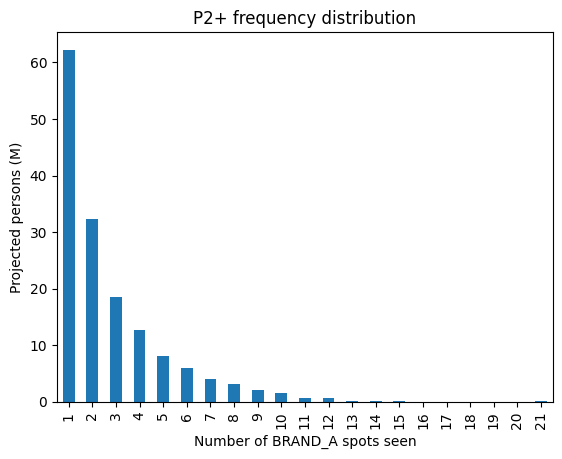

Median frequency: 2
Share of impressions at 5+ exposures: 0.444


In [35]:
e = expo[expo["P2+"]]
freq = e.groupby("respondent_id")["ad_airing_id"].nunique()   # spots seen per person
dist = (persons.loc[freq.index, "month_weight"].groupby(freq).sum() / 1e6).reindex(range(1, freq.max() + 1), fill_value=0)
dist.plot.bar(xlabel="Number of BRAND_A spots seen", ylabel="Projected persons (M)", title="P2+ frequency distribution")
plt.show()
print("Median frequency:", (dist.cumsum() / dist.sum() >= 0.5).idxmax())
print("Share of impressions at 5+ exposures:", f"{e.loc[e['respondent_id'].map(freq) >= 5, 'weight'].sum() / e['weight'].sum():.3f}")

**Answer:** No. The distribution is heavily skewed: of the roughly 152 M people reached (43.5% of P2+), about 62 M, four in ten, saw a single spot and about six in ten saw one or two, so the median is 2 spots, while a heavy-viewing minority saw 5 and up to 21 spots. That minority is under a fifth of the people reached, yet it absorbed 44.4% of all impressions. The average frequency (GRPs ÷ reach, about 3) blends the two groups into a "typical" viewer who saw three spots: it overstates what most people actually got and hides the impressions piled on heavy viewers. The distribution itself, or reach at 1+, 3+ and 5+ exposures, is the fair summary.

## Task 2.3 — On target?

In [36]:
print("Share of impressions on A18-49:", f"{a_imp / p2_imp:.3f}")
print("A18-49 share of all persons:", f"{universe_day['A18-49'].sum() / universe_day['P2+'].sum():.3f}")
on_target = brand.groupby("network_code")[["P2+ imp", "A18-49 imp"]].sum()
pd.DataFrame({"share_of_impressions": on_target["P2+ imp"] / p2_imp,
              "share_on_A18-49": on_target["A18-49 imp"] / on_target["P2+ imp"]}).round(3)

Share of impressions on A18-49: 0.194
A18-49 share of all persons: 0.423


,share_of_impressions,share_on_A18-49
network_code,,
ABC,0.225,0.180
BRAVO,0.012,0.554
CBS,0.212,0.154
FNC,0.138,0.047
FOOD,0.023,0.316
FOX,0.182,0.242
FX,0.020,0.651
HGTV,0.059,0.306
HIST,0.029,0.202


**Answer:** The plan under-delivered against its target: only 19.4% of its impressions went to adults 18–49, although they are 42.3% of all persons (an index of 46), so most of the money bought people outside the audience it was meant for. The big networks explain almost all of the gap. CBS (15.4% of their BRAND_A impressions on A18–49), ABC (18.0%) and Fox News (4.7%) together carried 57.5% of all impressions and account for about 70% of the shortfall, and FOX (24.2%) and NBC (18.9%) are below the target share too. Only FX (65.1%) and Bravo (55.4%) over-deliver the target, but together they carry about 3% of the impressions; HGTV (30.6%), Food (31.6%) and History (20.2%) are also below 42%.

## Task 3.1 — Cost

In [37]:
cost = brand["cost"].sum()
print("Campaign cost (USD):", f"{cost:.0f}")
print("P2+ CPM (USD):", f"{cost / p2_imp * 1000:.2f}")
print("P2+ CPP (USD):", f"{cost / p2_grps:.0f}")
print("A18-49 CPM (USD):", f"{cost / a_imp * 1000:.2f}")
print("A18-49 CPP (USD):", f"{cost / a_grps:.0f}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [38]:
by_net = brand.groupby("network_code").agg(spots=("cost", "size"), cost_usd=("cost", "sum"),
                                           p2_imp=("P2+ imp", "sum"), a1849_imp=("A18-49 imp", "sum"))
by_net["p2_cpm_usd"] = by_net["cost_usd"] / by_net["p2_imp"] * 1000
by_net["a1849_cpm_usd"] = by_net["cost_usd"] / by_net["a1849_imp"] * 1000
by_net[["p2_imp", "a1849_imp"]] /= 1e6
by_net.sort_values("cost_usd", ascending=False).round(2)

,spots,cost_usd,p2_imp,a1849_imp,p2_cpm_usd,a1849_cpm_usd
network_code,,,,,,
FOX,13,2434700.0,76.26,18.44,31.93,132.03
ABC,29,1625700.0,94.21,16.99,17.26,95.69
CBS,22,1488700.0,88.98,13.69,16.73,108.72
NBC,16,796800.0,41.44,7.83,19.23,101.72
FNC,40,526300.0,57.80,2.72,9.11,193.70
HGTV,39,230000.0,24.66,7.55,9.33,30.45
FOOD,33,96620.0,9.48,2.99,10.19,32.29
FX,38,92200.0,8.52,5.55,10.82,16.61
HIST,37,79640.0,12.33,2.48,6.46,32.05


**Answer:** The money went overwhelmingly to the big networks: of the \$7.42 M, FOX took 33% for just 13 spots (about \$187 K a spot), ABC 22%, CBS 20%, NBC 11% and Fox News 7%, i.e. 93% of the budget for 120 of the 300 spots, while the 180 spots on the five small networks cost 7%. For the target the cheapest networks were FX (A18–49 CPM \$16.61) and Bravo (\$17.61), then HGTV, History and Food (\$30–32); the four broadcast networks cost \$96–132 per thousand A18–49 impressions and Fox News \$193.70, almost 12 times FX. On P2+ the ranking is different (History \$6.46, Fox News \$9.11 and HGTV \$9.33 are cheapest, FOX \$31.93 the dearest), which is how a plan bought on P2+ can look cheap and still deliver its target expensively. The small networks' CPMs rest on a handful of panelists per spot (Task 5), so their exact ranking is indicative.

## Task 3.3 — Guarantee

In [39]:
owed = max(0, 150 - p2_grps)
print("Guarantee met:", p2_grps >= 150)
print("Make-good GRPs owed:", f"{owed:.1f}")
print("Value of make-goods (USD):", f"{owed * cost / p2_grps:.0f}")

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [40]:
big = brand.index[brand["network_code"].isin(BIG)]
small = brand.index[~brand["network_code"].isin(BIG)]
r_big, r_small = delivery(big, "P2+")[2], delivery(small, "P2+")[2]
overlap = r_big + r_small - p2_reach
added = p2_reach - r_big
print("Reach, big networks (%):", f"{r_big:.1f}")
print("Reach, small networks (%):", f"{r_small:.1f}")
print("Reach, whole campaign (%):", f"{p2_reach:.1f}")
print("Overlap (%):", f"{overlap:.1f}")
print("Overlap if independent (%):", f"{r_big * r_small / 100:.1f}")
print("Reach added by small networks (points):", f"{added:.1f}")
print("Cost per added reach point, small (USD):", f"{brand.loc[small, 'cost'].sum() / added:.0f}")
print("Cost per reach point, big (USD):", f"{brand.loc[big, 'cost'].sum() / r_big:.0f}")
print("Reached by big among those reached by small (%):", f"{overlap / r_small * 100:.1f}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456
Reached by big among those reached by small (%): 70.2


**Answer:** The big networks' spots reached 39.8% of persons and the small networks' 12.4%, yet the whole campaign reached 43.5%, not 52.2%, because reach counts every person once: the 8.7% of persons who saw spots in both groups are counted twice when the two reaches are added. The overlap is 1.8 times the 4.9% expected if the two audiences were independent: 70.2% of the people reached on the small networks were also reached on the big ones, against 39.8% of all persons. So small-network viewers were much more likely than average to be reached by the big networks, because exposure depends on how much TV a person watches: the heavy viewers who find their way to HGTV, FX or History also spend many hours with the big networks, so duplication is far from random. The small-network money was still well spent: \$548 K added 3.7 reach points (from 39.8% to 43.5%) at \$148,706 per added point, less than the \$172,456 that each reach point cost on the big networks on average (and the next point bought there would cost more still), and the small networks' audiences were twice as target-rich (36% of their impressions on A18–49 vs 17% on the big networks).

## Task 5 — How sure are we?

In [41]:
brand["panelists"] = expo.groupby("ad_airing_id").size().reindex(brand.index, fill_value=0)
brand["w1834_panelists"] = expo[expo["W18-34"]].groupby("ad_airing_id").size().reindex(brand.index, fill_value=0)
p = brand["P2+ rating"] / 100
brand["se"] = (p * (1 - p) / brand["broadcast_date"].map(n_day)) ** 0.5 * 100
brand["rel_se"] = brand["se"] / brand["P2+ rating"]                # undefined (NaN) when the rating is 0
display(brand.groupby("network_code")[["panelists", "rel_se"]].median().round(3))
print("Spots seen by no panelist:", (brand["panelists"] == 0).sum())
print("Median relative SE, big networks:", f"{brand.loc[big, 'rel_se'].median():.3f}")
print("Median relative SE, small networks:", f"{brand.loc[small, 'rel_se'].median():.3f}")
print("W18-34 zero-cell spots:", (brand["w1834_panelists"] == 0).sum())

,panelists,rel_se
network_code,,
ABC,57.0,0.123
BRAVO,3.0,0.540
CBS,69.0,0.113
FNC,31.0,0.164
FOOD,5.0,0.423
FOX,145.0,0.080
FX,5.5,0.423
HGTV,11.0,0.301
HIST,5.0,0.460


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A zero rating does not mean nobody saw the spot; it means none of the roughly 9,300 panelists in-tab that day did. On the big networks a spot stands on 31–145 panelists (median) and its rating has a median relative error of 12%, but a typical small-network spot is seen by only 3–11 panelists (Bravo 3, Food and History 5, FX 5.5, HGTV 11), so its rating moves in steps of one panelist (about 0.01 points) and its median relative error is 42%. Ten spots were seen by no panelist at all and get a rating of exactly 0.0, which is what happens when a spot's expected audience is a handful of panelists, as on the small networks: their spot ratings are mostly sampling noise, the SRS formula ignores weighting and household clustering so the true errors are larger still, and they should only be judged on many spots pooled (by network, daypart or month). For W18–34 it is worse: only about 950 women 18–34 are in-tab per day, and 171 of the 300 spots (57%) were seen by none of them. I would tell the client that W18–34 ratings by spot cannot be reported, because most cells are empty or rest on one or two panelists, and give W18–34 only for the whole campaign or by network over the month, with a margin of error.

## Bonus

In [42]:
worst = by_net[by_net["spots"] >= 20]["a1849_cpm_usd"].idxmax()
best = by_net["a1849_cpm_usd"].idxmin()
moved = brand[brand["network_code"] == worst].nlargest(20, "cost")
budget = moved["cost"].sum()
new_a_imp = a_imp - moved["A18-49 imp"].sum() + budget / by_net.loc[best, "a1849_cpm_usd"] * 1000
print(f"Move 20 spots ({budget:.0f} USD) from {worst} to {best}")
print("A18-49 CPM now (USD):", f"{cost / a_imp * 1000:.2f}")
print("A18-49 CPM after the move (USD):", f"{cost / new_a_imp * 1000:.2f}")

Move 20 spots (384000 USD) from FNC to FX
A18-49 CPM now (USD): 91.53
A18-49 CPM after the move (USD): 72.41


**Answer:** Move the 20 most expensive Fox News spots (\$384,000) to FX. Fox News is the worst buy for the target (A18–49 CPM \$193.70, only 4.7% of its impressions on A18–49) and FX the cheapest (A18–49 CPM \$16.61, 65% on A18–49), so at FX's CPM the same money buys about 23 M A18–49 impressions instead of the roughly 1.7 M those Fox News spots delivered. Target impressions rise by about a quarter and the campaign's A18–49 CPM falls from \$91.53 to \$72.41 (−21%) at the same total cost, and because two thirds of FX's audience is in the target, the extra spots should add A18–49 reach rather than more frequency on older viewers; P2+ delivery changes little, since FX's P2+ CPM (\$10.82) is close to Fox News's (\$9.11). FX's numbers rest on few panelists per spot (relative error about 42%), so I would split the money between FX and Bravo (A18–49 CPM \$17.61) and check the delivery after the flight.